# FIFA Moneyball: finding undervalued players

In this notebook I use the FIFA 22 player data to find out **how much a player should be worth** and **which players cost less than they should**.

**Steps:** look at the data, clean it, explore it with charts, use SQL, build a price model with NumPy, make the final charts, and pick a Budget XI.

**Data:** [FIFA 22 complete player dataset](https://www.kaggle.com/stefanoleone992/fifa-22-complete-player-dataset) on Kaggle (`players_22.csv`).
**Tools:** pandas, NumPy, matplotlib, seaborn, SQLite.

*Note:* I made this notebook in Google Colab. A few cells reload saved files (like `players_clean.csv`), because the Colab session resets and the variables are lost.

## 1. First look at the data
Checking the size, the columns, missing values, duplicates and the most expensive players.

In [1]:
import pandas as pd

df = pd.read_csv("players_22.csv", low_memory=False) #low memory means the pandas will read the file at once so the columns data type wont be wrong
df.shape #rows and cols

(19239, 110)

In [2]:
df.columns.tolist() #converts the column names to list

['sofifa_id',
 'player_url',
 'short_name',
 'long_name',
 'player_positions',
 'overall',
 'potential',
 'value_eur',
 'wage_eur',
 'age',
 'dob',
 'height_cm',
 'weight_kg',
 'club_team_id',
 'club_name',
 'league_name',
 'league_level',
 'club_position',
 'club_jersey_number',
 'club_loaned_from',
 'club_joined',
 'club_contract_valid_until',
 'nationality_id',
 'nationality_name',
 'nation_team_id',
 'nation_position',
 'nation_jersey_number',
 'preferred_foot',
 'weak_foot',
 'skill_moves',
 'international_reputation',
 'work_rate',
 'body_type',
 'real_face',
 'release_clause_eur',
 'player_tags',
 'player_traits',
 'pace',
 'shooting',
 'passing',
 'dribbling',
 'defending',
 'physic',
 'attacking_crossing',
 'attacking_finishing',
 'attacking_heading_accuracy',
 'attacking_short_passing',
 'attacking_volleys',
 'skill_dribbling',
 'skill_curve',
 'skill_fk_accuracy',
 'skill_long_passing',
 'skill_ball_control',
 'movement_acceleration',
 'movement_sprint_speed',
 'movement_agi

In [3]:
df.head(10)

,sofifa_id,player_url,short_name,long_name,player_positions,overall,potential,value_eur,wage_eur,age,...,lcb,cb,rcb,rb,gk,player_face_url,club_logo_url,club_flag_url,nation_logo_url,nation_flag_url
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,"RW, ST, CF",93,93,78000000.0,320000.0,34,...,50+3,50+3,50+3,61+3,19+3,https://cdn.sofifa.net/players/158/023/22_120.png,https://cdn.sofifa.net/teams/73/60.png,https://cdn.sofifa.net/flags/fr.png,https://cdn.sofifa.net/teams/1369/60.png,https://cdn.sofifa.net/flags/ar.png
1,188545,https://sofifa.com/player/188545/robert-lewand...,R. Lewandowski,Robert Lewandowski,ST,92,92,119500000.0,270000.0,32,...,60+3,60+3,60+3,61+3,19+3,https://cdn.sofifa.net/players/188/545/22_120.png,https://cdn.sofifa.net/teams/21/60.png,https://cdn.sofifa.net/flags/de.png,https://cdn.sofifa.net/teams/1353/60.png,https://cdn.sofifa.net/flags/pl.png
2,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,"ST, LW",91,91,45000000.0,270000.0,36,...,53+3,53+3,53+3,60+3,20+3,https://cdn.sofifa.net/players/020/801/22_120.png,https://cdn.sofifa.net/teams/11/60.png,https://cdn.sofifa.net/flags/gb-eng.png,https://cdn.sofifa.net/teams/1354/60.png,https://cdn.sofifa.net/flags/pt.png
3,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Júnior,"LW, CAM",91,91,129000000.0,270000.0,29,...,50+3,50+3,50+3,62+3,20+3,https://cdn.sofifa.net/players/190/871/22_120.png,https://cdn.sofifa.net/teams/73/60.png,https://cdn.sofifa.net/flags/fr.png,NaN,https://cdn.sofifa.net/flags/br.png
4,192985,https://sofifa.com/player/192985/kevin-de-bruy...,K. De Bruyne,Kevin De Bruyne,"CM, CAM",91,91,125500000.0,350000.0,30,...,69+3,69+3,69+3,75+3,21+3,https://cdn.sofifa.net/players/192/985/22_120.png,https://cdn.sofifa.net/teams/10/60.png,https://cdn.sofifa.net/flags/gb-eng.png,https://cdn.sofifa.net/teams/1325/60.png,https://cdn.sofifa.net/flags/be.png
5,200389,https://sofifa.com/player/200389/jan-oblak/220002,J. Oblak,Jan Oblak,GK,91,93,112000000.0,130000.0,28,...,33+3,33+3,33+3,32+3,89+3,https://cdn.sofifa.net/players/200/389/22_120.png,https://cdn.sofifa.net/teams/240/60.png,https://cdn.sofifa.net/flags/es.png,NaN,https://cdn.sofifa.net/flags/si.png
6,231747,https://sofifa.com/player/231747/kylian-mbappe...,K. Mbappé,Kylian Mbappé Lottin,"ST, LW",91,95,194000000.0,230000.0,22,...,54+3,54+3,54+3,63+3,18+3,https://cdn.sofifa.net/players/231/747/22_120.png,https://cdn.sofifa.net/teams/73/60.png,https://cdn.sofifa.net/flags/fr.png,https://cdn.sofifa.net/teams/1335/60.png,https://cdn.sofifa.net/flags/fr.png
7,167495,https://sofifa.com/player/167495/manuel-neuer/...,M. Neuer,Manuel Peter Neuer,GK,90,90,13500000.0,86000.0,35,...,34+3,34+3,34+3,35+3,88+2,https://cdn.sofifa.net/players/167/495/22_120.png,https://cdn.sofifa.net/teams/21/60.png,https://cdn.sofifa.net/flags/de.png,https://cdn.sofifa.net/teams/1337/60.png,https://cdn.sofifa.net/flags/de.png
8,192448,https://sofifa.com/player/192448/marc-andre-te...,M. ter Stegen,Marc-André ter Stegen,GK,90,92,99000000.0,250000.0,29,...,33+3,33+3,33+3,31+3,88+3,https://cdn.sofifa.net/players/192/448/22_120.png,https://cdn.sofifa.net/teams/241/60.png,https://cdn.sofifa.net/flags/es.png,NaN,https://cdn.sofifa.net/flags/de.png
9,202126,https://sofifa.com/player/202126/harry-kane/22...,H. Kane,Harry Kane,ST,90,90,129500000.0,240000.0,27,...,61+3,61+3,61+3,64+3,20+3,https://cdn.sofifa.net/players/202/126/22_120.png,https://cdn.sofifa.net/teams/18/60.png,https://cdn.sofifa.net/flags/gb-eng.png,https://cdn.sofifa.net/teams/1318/60.png,https://cdn.sofifa.net/flags/gb-eng.png


In [4]:
cols = ["short_name", "age", "club_name", "league_name",
        "player_positions", "overall", "potential", "value_eur", "wage_eur"]
df = df[cols]
df.head()

,short_name,age,club_name,league_name,player_positions,overall,potential,value_eur,wage_eur
0,L. Messi,34,Paris Saint-Germain,French Ligue 1,"RW, ST, CF",93,93,78000000.0,320000.0
1,R. Lewandowski,32,FC Bayern München,German 1. Bundesliga,ST,92,92,119500000.0,270000.0
2,Cristiano Ronaldo,36,Manchester United,English Premier League,"ST, LW",91,91,45000000.0,270000.0
3,Neymar Jr,29,Paris Saint-Germain,French Ligue 1,"LW, CAM",91,91,129000000.0,270000.0
4,K. De Bruyne,30,Manchester City,English Premier League,"CM, CAM",91,91,125500000.0,350000.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19239 entries, 0 to 19238
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   short_name        19239 non-null  object 
 1   age               19239 non-null  int64  
 2   club_name         19178 non-null  object 
 3   league_name       19178 non-null  object 
 4   player_positions  19239 non-null  object 
 5   overall           19239 non-null  int64  
 6   potential         19239 non-null  int64  
 7   value_eur         19165 non-null  float64
 8   wage_eur          19178 non-null  float64
dtypes: float64(2), int64(3), object(4)
memory usage: 1.3+ MB


In [6]:
df.isna().sum() #null values and its sum (column)

,0
short_name,0
age,0
club_name,61
league_name,61
player_positions,0
overall,0
potential,0
value_eur,74
wage_eur,61


In [7]:
(df.isna().mean() * 100).round(1) #percentage of how many null values present in each column

,0
short_name,0.0
age,0.0
club_name,0.3
league_name,0.3
player_positions,0.0
overall,0.0
potential,0.0
value_eur,0.4
wage_eur,0.3


In [8]:
df.describe() #show statistical overview of the table

,age,overall,potential,value_eur,wage_eur
count,19239.000000,19239.000000,19239.000000,1.916500e+04,19178.000000
mean,25.210822,65.772182,71.079370,2.850452e+06,9017.989363
std,4.748235,6.880232,6.086213,7.613700e+06,19470.176724
min,16.000000,47.000000,49.000000,9.000000e+03,500.000000
25%,21.000000,61.000000,67.000000,4.750000e+05,1000.000000
50%,25.000000,66.000000,71.000000,9.750000e+05,3000.000000
75%,29.000000,70.000000,75.000000,2.000000e+06,8000.000000
max,54.000000,93.000000,95.000000,1.940000e+08,350000.000000


In [9]:
(df["value_eur"] == 0).sum()

np.int64(0)

In [10]:
df["value_eur"].isna().sum()

np.int64(74)

In [11]:
df.sort_values("value_eur", ascending=False).head() #sorting values (by the price in euros)

,short_name,age,club_name,league_name,player_positions,overall,potential,value_eur,wage_eur
6,K. Mbappé,22,Paris Saint-Germain,French Ligue 1,"ST, LW",91,95,194000000.0,230000.0
29,E. Haaland,20,Borussia Dortmund,German 1. Bundesliga,ST,88,93,137500000.0,110000.0
9,H. Kane,27,Tottenham Hotspur,English Premier League,ST,90,90,129500000.0,240000.0
3,Neymar Jr,29,Paris Saint-Germain,French Ligue 1,"LW, CAM",91,91,129000000.0,270000.0
4,K. De Bruyne,30,Manchester City,English Premier League,"CM, CAM",91,91,125500000.0,350000.0


In [12]:
df.duplicated().sum() #how many are duplicated and their sum (of the true values)

np.int64(0)

In [13]:
df["player_positions"].head(10)

,player_positions
0,"RW, ST, CF"
1,ST
2,"ST, LW"
3,"LW, CAM"
4,"CM, CAM"
5,GK
6,"ST, LW"
7,GK
8,GK
9,ST


In [14]:
df["gap"] = df["potential"] - df["overall"]
(df["gap"] == 0).mean() * 100

np.float64(33.31254223192474)

In [15]:
df.groupby("age")["gap"].mean().round(1)

,gap
age,
16,20.2
17,18.2
18,16.0
19,14.1
20,11.9
21,9.5
22,8.3
23,6.8
24,5.3




*   There are 19239 rows(number of players too) and 110 columns in the file
*   Most missing values are in column name -> value_eur	with 0.4%


*   There are no players whose values is 0 and there are 74 records where player's values are missing or null
*   As the players grow in age there gap in the potential and overall rating decreases





## 2. Data cleaning
Removing the players with no value and adding new columns: main position, position group, age group, gap (potential minus overall) and value in million euro.

In [16]:
df_clean=df.dropna(subset=['value_eur']).copy()  #subset tells specific column to check and a copy is made so original is safe
df_clean.shape #rows and cols

(19165, 10)

In [17]:
df_clean.isna().sum()
#if there were some null values i would fill unknown by fillna('unknown') except for wage_eur as it would not be right for further analysis

,0
short_name,0
age,0
club_name,0
league_name,0
player_positions,0
overall,0
potential,0
value_eur,0
wage_eur,0
gap,0


In [18]:
df_clean.duplicated().sum()

np.int64(0)

As there are no duplicates but if it were there i would use df_clean.drop_duplicates()

In [19]:
df_clean["main_position"] = df_clean["player_positions"].str.split(",").str[0].str.strip()
df_clean["main_position"].value_counts() #converts the text string into list separated by comma
#.str[0] takes first element of the list column if we dont write .str infront it would be row wise

,count
main_position,
CB,3321
ST,2599
CM,2169
GK,2124
CDM,1658
LB,1358
RB,1338
CAM,1144
RM,1026


In [20]:
group_map = {
    "GK": "GK",
    "CB": "DEF", "LB": "DEF", "RB": "DEF", "LWB": "DEF", "RWB": "DEF",
    "CDM": "MID", "CM": "MID", "CAM": "MID", "LM": "MID", "RM": "MID",
    "LW": "ATT", "RW": "ATT", "ST": "ATT", "CF": "ATT",
}
df_clean["position_group"] = df_clean["main_position"].map(group_map)
df_clean["position_group"].isna().sum()
# groups 15 specific player positions into 4 broad categories: Goalkeeper (GK), Defender (DEF), Midfielder (MID), and Attacker (ATT).
#CB: Abbreviation for DEF (usually before the goalkeeper to block the shots)
#CDM: Abbreviation for MID (Sits in front of the defenders to break up attacks.)

np.int64(0)

In [21]:
df_clean['age_group']=pd.cut(df['age'],bins=[0,21,29,100],labels=['16-21','22-29','30+'])
df_clean['age_group'].value_counts()

,count
age_group,
22-29,10339
16-21,5044
30+,3782


In [22]:
df_clean['gap']=df['potential']-df['overall']
df_clean['value_m']=df['value_eur']/1_000_000

In [23]:
df_clean[["age", "overall", "potential", "gap", "value_m"]].describe().round(2)

,age,overall,potential,gap,value_m
count,19165.00,19165.00,19165.00,19165.00,19165.00
mean,25.19,65.76,71.08,5.32,2.85
std,4.73,6.88,6.09,5.52,7.61
min,16.00,47.00,49.00,0.00,0.01
25%,21.00,61.00,67.00,0.00,0.48
50%,25.00,66.00,71.00,4.00,0.98
75%,29.00,70.00,75.00,9.00,2.00
max,43.00,93.00,95.00,26.00,194.00


In [24]:
df_clean.groupby('position_group')['value_m'].agg(['count','mean','median']).round(2)

,count,mean,median
position_group,,,
ATT,3666,3.45,1.10
DEF,6366,2.53,0.95
GK,2124,1.93,0.50
MID,7009,3.11,1.10


In [25]:
df_clean.to_csv("players_clean.csv", index=False)

from google.colab import files
files.download("players_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 3. Exploring the data
Charts and summaries by position, age and league, plus a correlation table.
*(The next cell reloads the cleaned file in case the Colab session was reset.)*

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df_clean = pd.read_csv("players_clean.csv")
df_clean.shape

(19165, 14)

Having count,mean,median of the positions

In [27]:
pos_summary= df_clean.groupby('position_group').agg(
    players= ('short_name','count'),
    avg_overall =('overall','mean'),
    median_value=('value_m','median'),
    mean_value=('value_m','mean')
).round(2)
pos_summary

,players,avg_overall,median_value,mean_value
position_group,,,,
ATT,3666,65.91,1.10,3.45
DEF,6366,65.87,0.95,2.53
GK,2124,64.40,0.50,1.93
MID,7009,66.00,1.10,3.11


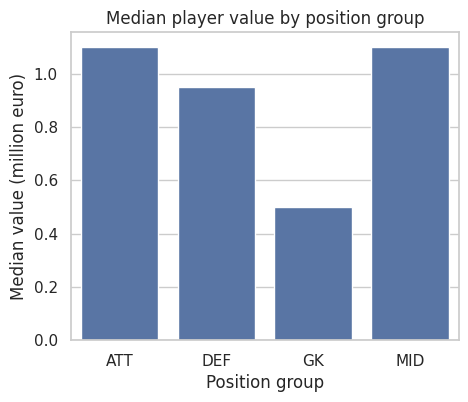

In [28]:
plt.figure(figsize=(5,4))
sns.barplot(x=pos_summary.index,y=pos_summary['median_value'])
plt.title("Median player value by position group")
plt.xlabel("Position group")
plt.ylabel("Median value (million euro)")
plt.show()

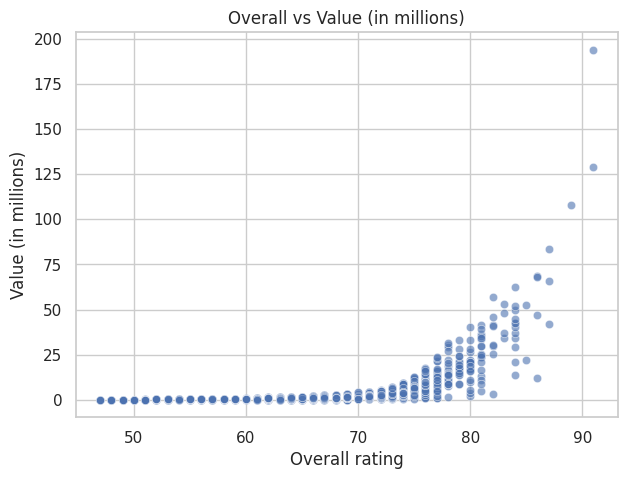

In [29]:
sample= df_clean.sample(3000,random_state=42) #out of 19,165 3000 will be picked out and random state is 42 so that everytime that 3000 is picked out

plt.figure(figsize=(7, 5))
sns.scatterplot(data=sample , x='overall',y='value_m',alpha=0.6)
plt.title('Overall vs Value (in millions)')
plt.xlabel('Overall rating')
plt.ylabel('Value (in millions)')
plt.show()

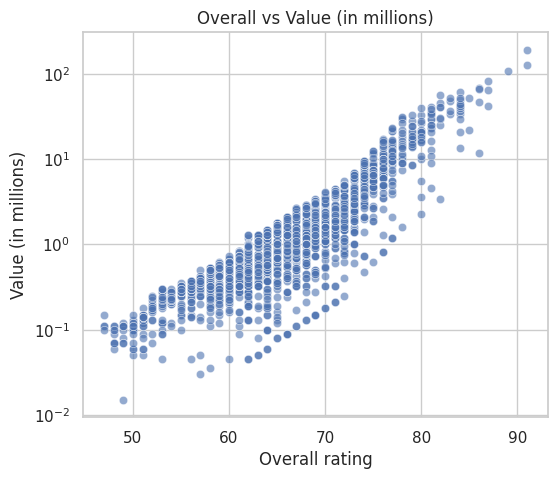

In [30]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=sample , x='overall',y='value_m',alpha=0.6)
plt.yscale('log') #so that value increases 10X everytime and easy to interpret
plt.title('Overall vs Value (in millions)')
plt.xlabel('Overall rating')
plt.ylabel('Value (in millions)')
plt.show()

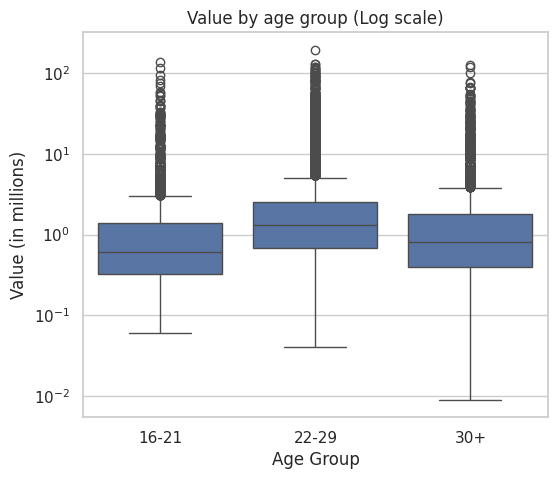

In [31]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df_clean , x='age_group',y='value_m' ,order=["16-21", "22-29", "30+"])
plt.yscale('log')
plt.title('Value by age group (Log scale)')
plt.xlabel('Age Group')
plt.ylabel('Value (in millions)')
plt.show()

In [32]:
league_summary= df_clean[df_clean['league_name'] != 'Unknown'].groupby('league_name').agg(
    players= ('short_name','count'),
    avg_overall=('overall','mean') ,
    median_value=('value_m','median')
).round(2)
league_summary= league_summary[league_summary['players']>=100]
league_summary.sort_values('median_value',ascending=False).head(10)

,players,avg_overall,median_value
league_name,,,
English Premier League,652,72.50,5.5
Spain Primera Division,633,73.47,5.0
Italian Serie A,563,72.86,3.9
German 1. Bundesliga,551,71.32,3.1
French Ligue 1,577,70.88,2.8
Greek Super League,112,70.79,2.4
Campeonato Brasileiro Série A,360,71.75,2.1
Portuguese Liga ZON SAGRES,505,68.94,1.8
Turkish Süper Lig,542,68.37,1.5


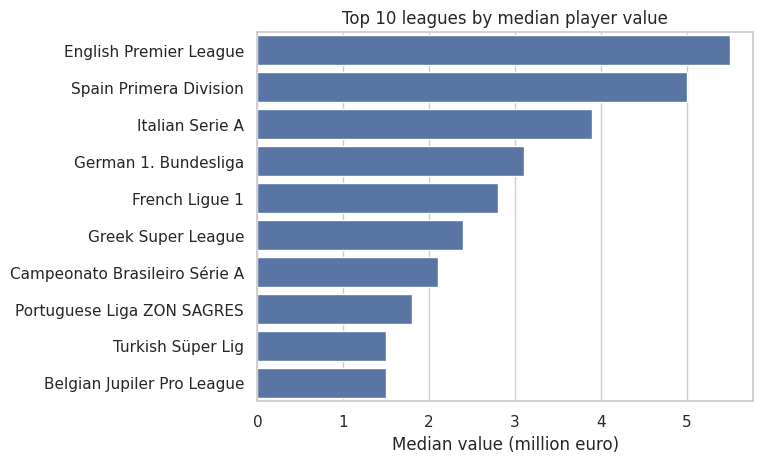

In [33]:
top10 = league_summary.sort_values('median_value',ascending=False).head(10)
sns.barplot(x=top10["median_value"], y=top10.index)
plt.title("Top 10 leagues by median player value")
plt.xlabel("Median value (million euro)")
plt.ylabel("")
plt.show()

In [34]:
df_clean['log_value']= np.log(df_clean['value_eur'])

corr_cols=['age','overall','gap','potential','wage_eur','value_eur','log_value']
df_clean[corr_cols].corr().round(2)
#correlation lies between -1 and 1 so
#-1 means one increases and one decreases
# 0 means no correlation
# +1 means both parameters increase together

,age,overall,gap,potential,wage_eur,value_eur,log_value
age,1.00,0.46,-0.87,-0.26,0.16,0.04,0.04
overall,0.46,1.00,-0.54,0.64,0.60,0.55,0.89
gap,-0.87,-0.54,1.00,0.30,-0.20,-0.11,-0.19
potential,-0.26,0.64,0.30,1.00,0.50,0.53,0.83
wage_eur,0.16,0.60,-0.20,0.50,1.00,0.82,0.64
value_eur,0.04,0.55,-0.11,0.53,0.82,1.00,0.65
log_value,0.04,0.89,-0.19,0.83,0.64,0.65,1.00


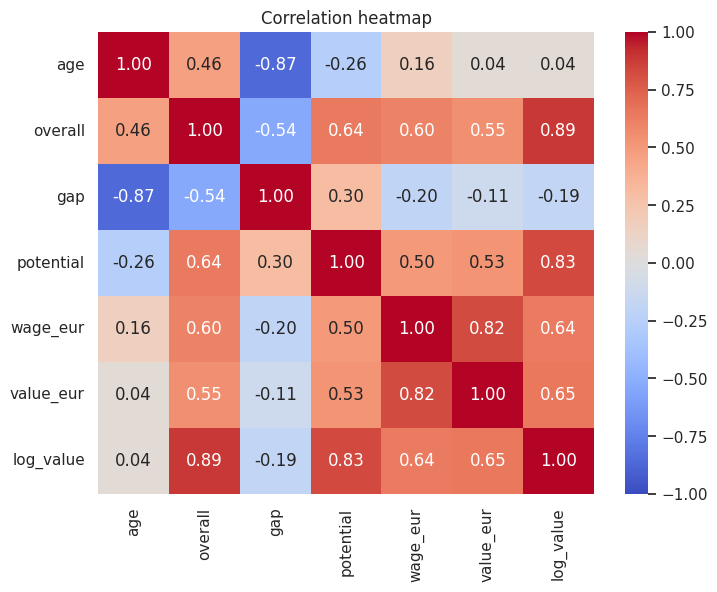

In [35]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.show()

## 4. SQL queries (SQLite)
I put the clean table into a small SQLite database and use SQL for group summaries, club squad values, and window functions (`row_number` with `partition by`, and a window average).

In [36]:
import pandas as pd
import numpy as np
import sqlite3

df_clean = pd.read_csv("players_clean.csv")
df_clean.shape

(19165, 14)

In [37]:
conn = sqlite3.connect("fifa.db") #creating fifa database
df_clean.to_sql("players", conn, if_exists="replace", index=False) #players table name in fifa data base

19165

In [38]:
def q(sql):
    return pd.read_sql(sql, conn)

q("select count(*) as total_players from players")

,total_players
0,19165


In [39]:
q("""
select position_group, count(*) as players, round(avg(overall),2) as avg_overall , round(avg(value_m),2) as avg_value_m
from players
group by position_group
order by avg_value_m desc """
)

,position_group,players,avg_overall,avg_value_m
0,ATT,3666,65.91,3.45
1,MID,7009,66.00,3.11
2,DEF,6366,65.87,2.53
3,GK,2124,64.40,1.93


In [40]:
q("""
select club_name,
       count(*) as players,
       round(sum(value_m), 1) as squad_value_m
from players
where club_name != 'Unknown'
group by club_name
having count(*) >= 20
order by squad_value_m desc
limit 10
""")

,club_name,players,squad_value_m
0,Manchester City,32,1299.5
1,Paris Saint-Germain,33,1227.4
2,Liverpool,33,1046.4
3,Manchester United,33,1008.7
4,Real Madrid CF,33,987.6
5,FC Bayern München,28,969.5
6,Atlético de Madrid,32,952.5
7,Chelsea,33,934.1
8,FC Barcelona,33,834.3
9,Juventus,26,774.9


In [41]:
q("""
with ranked as (
  select short_name, position_group, overall, value_m,
         row_number() over (
           partition by position_group
           order by overall desc, value_m asc
         ) as rn
  from players
)
select * from ranked
where rn <= 3
order by position_group, rn
""")

,short_name,position_group,overall,value_m,rn
0,L. Messi,ATT,93,78.0,1
1,R. Lewandowski,ATT,92,119.5,2
2,Cristiano Ronaldo,ATT,91,45.0,3
3,V. van Dijk,DEF,89,86.0,1
4,Sergio Ramos,DEF,88,24.0,2
5,A. Robertson,DEF,87,83.5,3
6,J. Oblak,GK,91,112.0,1
7,M. Neuer,GK,90,13.5,2
8,M. ter Stegen,GK,90,99.0,3
9,K. De Bruyne,MID,91,125.5,1


In [42]:
cheap = q("""
with compare as (
  select short_name, club_name, age, position_group, overall, value_m,
         avg(value_m) over (partition by position_group, overall) as avg_value,
         count(*) over (partition by position_group, overall) as n
  from players
)
select short_name, club_name, age, position_group, overall, value_m,
       round(avg_value, 2) as avg_value,
       round(value_m - avg_value, 2) as diff
from compare
where n >= 5 and overall >= 75
order by diff asc
limit 15
""")
cheap

,short_name,club_name,age,position_group,overall,value_m,avg_value,diff
0,L. Modrić,Real Madrid CF,35,MID,87,32.0,83.71,-51.71
1,G. Chiellini,Juventus,36,DEF,86,12.0,56.19,-44.19
2,Thiago Silva,Chelsea,36,DEF,85,9.5,43.29,-33.79
3,Fernandinho,Manchester City,36,MID,83,7.0,38.63,-31.63
4,David Silva,Real Sociedad,35,MID,85,22.0,52.95,-30.95
5,Fernando,Sevilla FC,33,MID,84,21.0,51.07,-30.07
6,E. Cavani,Manchester United,34,ATT,85,26.0,55.88,-29.88
7,Pepe,FC Porto,38,DEF,82,5.5,34.29,-28.79
8,E. Džeko,Inter,35,ATT,83,15.5,43.18,-27.68
9,Raúl Albiol,Villarreal CF,35,DEF,82,8.0,34.29,-26.29


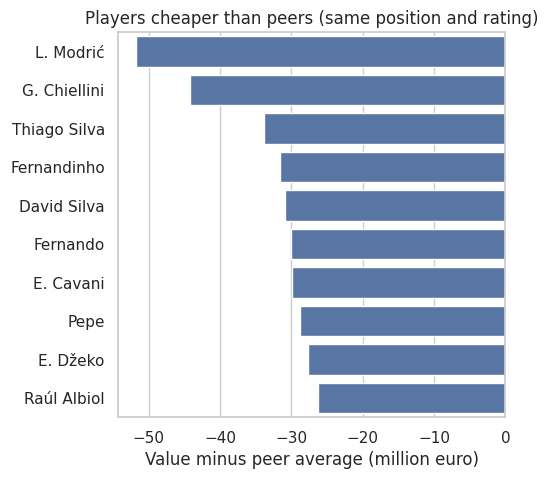

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

top = cheap.head(10)
plt.figure(figsize=(5, 5))
sns.barplot(data=top, x="diff", y="short_name")
plt.title("Players cheaper than peers (same position and rating)")
plt.xlabel("Value minus peer average (million euro)")
plt.ylabel("")
plt.show()

## 5. Price model (NumPy)
I use the **log of value**, because value grows by percentages (a higher rating multiplies the price) and not by fixed amounts. After taking the log the pattern is close to a straight line.

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df_clean = pd.read_csv("players_clean.csv")
df_clean["log_value"] = np.log(df_clean["value_eur"])
df_clean.shape

(19165, 15)

### Model 1: rating only
How much does the value change when the rating goes up by one point?

In [45]:
#when rating increases by how much the value increases
x = df_clean["overall"].to_numpy() #converts into array
y = df_clean["log_value"].to_numpy()

slope, intercept = np.polyfit(x, y, 1) #1 is degree here it represents y=mx+c
slope, intercept

(np.float64(0.15850466098906635), np.float64(3.4628070445147703))

In [46]:
#how good the model can perform (linear regression)
def r_squared(y_true,y_pred):
  ss_res = np.sum((y_true - y_pred) **2 )
  ss_tot = np.sum((y_true - y_true.mean()) **2 )
  return 1 - ss_res/ss_tot

pred1 = slope * x + intercept
r_squared(y, pred1)

np.float64(0.7862949918764066)

### Model 2: rating, age, gap and position
Value also depends on age (I use age and age squared) and position. Position is turned into 0/1 columns because the model only understands numbers.

In [47]:
#value also changes with the age and position
age=df_clean['age'].to_numpy()
gap=df_clean['gap'].to_numpy()
pos=pd.get_dummies(df_clean['position_group'],drop_first=True).to_numpy(dtype=float) #get dummies put 0/1 instead of text as ml models only recognize the 0/1 values and
#drop_first=True drops one of the 0/1 columns (it can be worked out from the others)

X=np.column_stack([np.ones(len(df_clean)),x,age,gap,age**2,pos]) #np.ones makes a column of 1s (for the starting value, called the intercept)
X.shape

(19165, 8)

In [48]:
coef, *_ = np.linalg.lstsq(X, y, rcond=None) #X holds the inputs (1, rating, age, gap, age², position), *_ means ignore the extra values, coef is the weights
#y is the log of player value, so the pattern with rating becomes close to a straight line. linalg is linear algebra and lstsq is the least squares method
#@ is matrix multiplication, like pred2 = 1*b0 + rating*b1 + age*b2 ...

pred2 = X @ coef
r_squared(y, pred2)

np.float64(0.9726101414762366)

### Fair value and undervalued players
The model gives a fair value for every player. The discount is how much cheaper the real value is than the fair value. I only look at players with rating 75 or more and value 3M or more, so very cheap players do not look like bargains just because of rounding.

In [49]:
#converting models prediction into million euro to see how much original value is less or more
df_clean['fair_value_m']=np.exp(pred2)/1_000_000
df_clean['discount_pct']= (1- df_clean['value_m']/df_clean['fair_value_m'])*100
df_clean[['short_name','age','overall','value_m','fair_value_m','discount_pct']]

,short_name,age,overall,value_m,fair_value_m,discount_pct
0,L. Messi,34,93,78.00,76.445099,-2.034010
1,R. Lewandowski,32,92,119.50,87.298181,-36.887158
2,Cristiano Ronaldo,36,91,45.00,35.218759,-27.772815
3,Neymar Jr,29,91,129.00,105.312988,-22.492014
4,K. De Bruyne,30,91,125.50,89.706948,-39.899978
...,...,...,...,...,...,...
19160,Song Defu,22,47,0.07,0.036610,-91.202401
19161,C. Porter,19,47,0.11,0.050438,-118.090917
19162,N. Logue,21,47,0.10,0.042830,-133.481568
19163,L. Rudden,19,47,0.11,0.055789,-97.171073


In [50]:
#Top 20 undervalued players
candidates = df_clean[(df_clean["overall"] >= 75) & (df_clean["value_m"] >= 3)]
top20 = candidates.sort_values("discount_pct", ascending=False).head(20)
top20[["short_name", "club_name", "age", "position_group", "overall", "potential",
       "value_m", "fair_value_m", "discount_pct"]].round(1)

,short_name,club_name,age,position_group,overall,potential,value_m,fair_value_m,discount_pct
7,M. Neuer,FC Bayern München,35,GK,90,90,13.5,26.2,48.4
26,K. Navas,Paris Saint-Germain,34,GK,88,88,15.5,21.3,27.3
200,Ł. Fabiański,West Ham United,36,GK,82,82,3.4,4.5,24.6
201,S. Sirigu,Genoa,34,GK,82,82,5.0,6.6,24.6
70,K. Schmeichel,Leicester City,34,GK,85,85,9.0,11.9,24.3
48,S. Handanovič,Inter,36,GK,86,86,7.5,9.8,23.7
31,H. Lloris,Tottenham Hotspur,34,GK,87,87,13.5,17.6,23.1
410,Guaita,Crystal Palace,34,GK,80,80,3.6,4.5,19.9
451,F. Armani,River Plate,34,GK,80,80,3.6,4.5,19.9
294,Adán,Sporting CP,34,GK,81,81,4.4,5.5,19.4


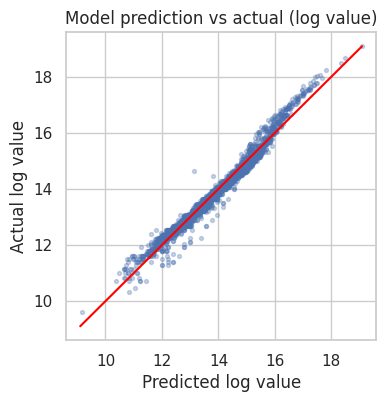

In [51]:
df_clean["pred_log"] = pred2
s = df_clean.sample(3000, random_state=42)

plt.figure(figsize=(4, 4))
plt.scatter(s["pred_log"], s["log_value"], alpha=0.3, s=8)
lims = [df_clean["log_value"].min(), df_clean["log_value"].max()]
plt.plot(lims, lims, color="red")
plt.title("Model prediction vs actual (log value)")
plt.xlabel("Predicted log value")
plt.ylabel("Actual log value")
plt.show()

In [52]:
df_clean.to_csv("players_scored.csv", index=False)

from google.colab import files
files.download("players_scored.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Final charts
This cell loads the scored data (`players_scored.csv`) saved above and makes the charts used in the README.

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("players_scored.csv")
needed= ['short_name','age','age_group','club_name','position_group','overall','potential','value_m','log_value','fair_value_m','discount_pct','pred_log']
[c for c in needed if c not in df.columns]

[]

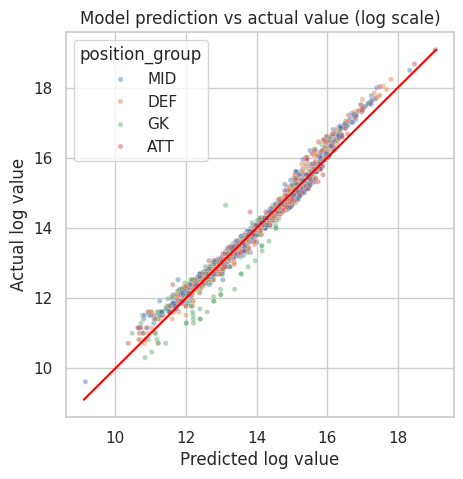

In [62]:
#model accuracy
s = df.sample(3000, random_state=42)

fig, ax = plt.subplots(figsize=(5, 5))
sns.scatterplot(data=s, x="pred_log", y="log_value", hue="position_group", alpha=0.45, s=14, ax=ax) #hue for every group diff color
lims = [df["log_value"].min(), df["log_value"].max()]
ax.plot(lims, lims, color="red", lw=1.5)
ax.set_title("Model prediction vs actual value (log scale)")
ax.set_xlabel("Predicted log value")
ax.set_ylabel("Actual log value")
fig.savefig("chart1_model_fit.png", dpi=150, bbox_inches="tight")
plt.show()

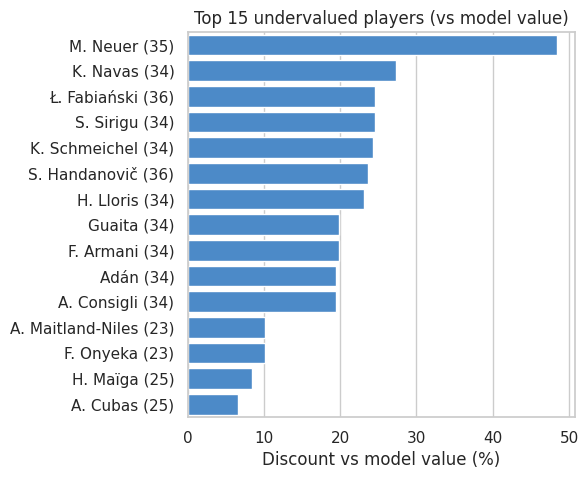

In [65]:
#top 15 undervalued players
cand = df[(df["overall"] >= 75) & (df["value_m"] >= 3)]
top15 = cand.sort_values("discount_pct", ascending=False).head(15).copy()
top15["label"] = top15["short_name"] + " (" + top15["age"].astype(str) + ")"

fig, ax = plt.subplots(figsize=(5, 5))
sns.barplot(data=top15, x="discount_pct", y="label", color="#378ADD", ax=ax)
ax.set_title("Top 15 undervalued players (vs model value)")
ax.set_xlabel("Discount vs model value (%)")
ax.set_ylabel("")
fig.savefig("chart2_top_undervalued.png", dpi=150, bbox_inches="tight")
plt.show()

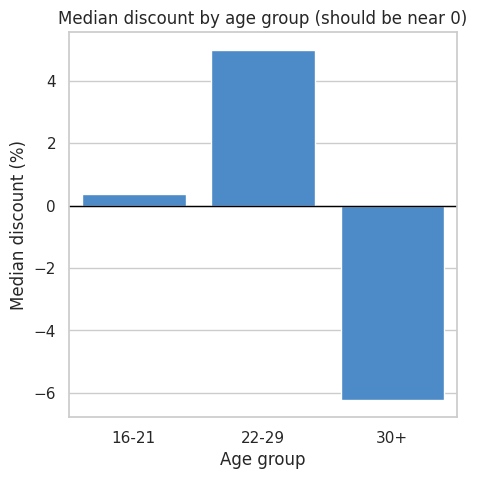

In [68]:
#is model same for the every age group
order = ["16-21", "22-29", "30+"]
fair = df.groupby("age_group")["discount_pct"].median().reindex(order)

fig, ax = plt.subplots(figsize=(5, 5))
sns.barplot(x=fair.index, y=fair.values, color="#378ADD", ax=ax)
ax.axhline(0, color="black", lw=1) #axhline means at 0 at horizontal line
ax.set_title("Median discount by age group (should be near 0)")
ax.set_xlabel("Age group")
ax.set_ylabel("Median discount (%)")
fig.savefig("chart3_fairness_by_age.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Budget XI
I pick the best 11 players in a 4-3-3 formation (1 GK, 4 DEF, 3 MID, 3 ATT). First with no price limit (Dream XI), then with a limit on the value of each player. If two players have the same rating, the cheaper one is picked.

In [69]:
formation = {"GK": 1, "DEF": 4, "MID": 3, "ATT": 3}

def pick_xi(data):
    parts = []
    for group, n in formation.items():
        best = (data[data["position_group"] == group]
                .sort_values(["overall", "value_m"], ascending=[False, True])
                .head(n))
        parts.append(best)
    return pd.concat(parts)

In [70]:
dream_xi = pick_xi(df)
budget_xi = pick_xi(df[df["value_m"] <= 10])

def summary(name, xi):
    return {"team": name,
            "total_cost_m": xi["value_m"].sum(),
            "avg_overall": xi["overall"].mean(),
            "avg_age": xi["age"].mean()}

pd.DataFrame([summary("Dream XI (no cap)", dream_xi),
              summary("Budget XI (10M cap)", budget_xi)]).round(1)

,team,total_cost_m,avg_overall,avg_age
0,Dream XI (no cap),952.0,89.8,30.6
1,Budget XI (10M cap),81.6,81.7,36.3


In [71]:
cols = ["short_name", "club_name", "position_group", "age", "overall", "value_m"]
budget_xi[cols].sort_values("position_group")

,short_name,club_name,position_group,age,overall,value_m
397,D. Payet,Olympique de Marseille,ATT,34,80,10.0
509,F. Ribéry,US Salernitana 1919,ATT,38,79,6.0
539,L. Rodríguez,Gimnasia y Esgrima La Plata,ATT,36,79,6.0
71,Thiago Silva,Chelsea,DEF,36,85,9.5
198,Pepe,FC Porto,DEF,38,82,5.5
199,Raúl Albiol,Villarreal CF,DEF,35,82,8.0
291,José Fonte,LOSC Lille,DEF,37,81,4.6
48,S. Handanovič,Inter,GK,36,86,7.5
140,Fernandinho,Manchester City,MID,36,83,7.0
283,Joaquín,Real Betis Balompié,MID,39,81,8.5


In [72]:
rows = []
for cap in [2, 5, 10, 15, 20, 30, 50, 100, 300]:
    xi = pick_xi(df[df["value_m"] <= cap])
    rows.append({"cap_m": cap,
                 "total_cost_m": xi["value_m"].sum(),
                 "avg_overall": xi["overall"].mean()})
curve = pd.DataFrame(rows).round(1)
curve

,cap_m,total_cost_m,avg_overall
0,2,16.0,75.6
1,5,42.8,78.4
2,10,81.6,81.7
3,15,128.5,83.7
4,20,147.0,84.1
5,30,210.0,85.5
6,50,378.5,87.3
7,100,749.5,89.2
8,300,952.0,89.8


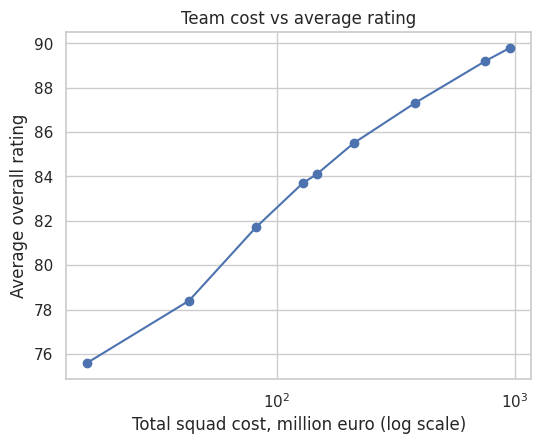

In [75]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(curve["total_cost_m"], curve["avg_overall"], marker="o")
ax.set_xscale("log")
ax.set_title("Team cost vs average rating")
ax.set_xlabel("Total squad cost, million euro (log scale)")
ax.set_ylabel("Average overall rating")
fig.savefig("chart4_cost_vs_rating.png", dpi=150, bbox_inches="tight")
plt.show()

### Download the charts (Colab only)
This cell works only inside Google Colab. It downloads the charts so I can upload them to GitHub.

In [77]:
from google.colab import files
for f in ["chart1_model_fit.png", "chart2_top_undervalued.png",
          "chart3_fairness_by_age.png", "chart4_cost_vs_rating.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Key findings

- **Rating and value:** rating has a correlation of 0.55 with value, but 0.89 with the log of value. This is why the log scale and the log model work better.
- **Position:** attackers, midfielders and defenders have almost the same average rating (about 66), but the average value is 3.45M for attackers, 3.11M for midfielders, 2.53M for defenders and 1.93M for goalkeepers.
- **League:** the Premier League has the highest median value (5.5M), followed by La Liga (5.0M) and Serie A (3.9M).
- **Age:** the gap between potential and overall gets smaller as players get older (correlation of -0.87).
- **Model:** each extra rating point raises the value by about 17%. R² goes from 0.79 (rating only) to 0.97 (rating, age, gap and position).
- **Undervalued players:** the top of the list is mostly goalkeepers aged 34 to 36, for example Neuer (13.5M against a model value of 26.2M). After them come younger midfielders and defenders with a discount of about 8-10%.
- **Fairness by age:** the median discount is close to 0% for ages 16-21, about +5% for 22-29 and about -6% for 30+, so a small age bias is left.
- **Budget XI:** the team with no limit costs 952.0M with an average rating of 89.8 (average age 30.6). With a 10M limit per player it costs 81.6M (about 91% less) with an average rating of 81.7, but the average age is 36.3.
- **Cost and rating:** paying more gives less and less extra rating. A 100M limit costs 749.5M for a rating of 89.2, and no limit costs 952.0M for 89.8.

## 9. Limits of this project

- FIFA values come from the game, not from the real transfer market, so the model partly learns how the game sets prices. "Undervalued" only means cheaper than **this model** says.
- The model only knows rating, age, potential and position. It does not know contracts, injuries or what a club needs.
- Goalkeepers dominate the undervalued list. A likely reason is that the model uses one age curve for all positions, while goalkeepers play well for longer. A separate age curve for goalkeepers would be a good next step.
- R² was checked on the same data the model learned from. A proper train and test split would be better.
- The Budget XI is old, because older players have low values. That makes it cheap, but not always a real bargain.